In [1]:
#Week 1 work
# Reproduction targets from Meyer et al. (2019) and Table S6
PAPER_FILTERED_GENES <- 16581
PAPER_SIG_GENES      <- 5141
MY_SIG_GENES         <- 5127

library(edgeR)
library(readxl)

# 1. Load author's count matrix
author_df <- read.delim("../data/GSE117588_organoids-gene-counts.tsv.gz", check.names = FALSE, row.names = 1)
counts <- as.matrix(author_df)

# 2. Load metadata and align rows to match count matrix columns
metadata <- read.csv("../metadata/samples.csv", check.names = FALSE)
metadata <- metadata[match(colnames(counts), metadata$count_column), ]
rownames(metadata) <- metadata$count_column
stopifnot(identical(rownames(metadata), colnames(counts)))

# 3. Set group as a factor with E3E3_ISO as the reference level
metadata$group <- factor(metadata$group, levels = c("E3E3_ISO", "E4E4_CTR"))
levels(metadata$group)
table(metadata$group, useNA = "ifany")

# 4. Build DGEList container
y <- DGEList(counts = counts, samples = metadata)
dim(y)
y$samples



Loading required package: limma



[1] "E3E3_ISO" "E4E4_CTR"


E3E3_ISO E4E4_CTR 
       3        3 

[1] 58395     6

,group,lib.size,norm.factors,run,sample,replicate,count_column
,<fct>,<dbl>,<dbl>,<chr>,<chr>,<int>,<chr>
ADR_11,E4E4_CTR,10542703,1,SRR7586681,GSM3304324,1,ADR_11
ADR_12,E4E4_CTR,9078713,1,SRR7586682,GSM3304325,2,ADR_12
ADR_13,E3E3_ISO,12052765,1,SRR7586683,GSM3304326,1,ADR_13
ADR_14,E3E3_ISO,12971384,1,SRR7586684,GSM3304327,2,ADR_14
ADR_5,E4E4_CTR,10305621,1,SRR7586685,GSM3304328,3,ADR_5
ADR_6,E3E3_ISO,11800476,1,SRR7586686,GSM3304329,3,ADR_6


In [2]:
# 5. Filter: keep genes with >= 1 CPM in at least 3 samples
keep <- rowSums(cpm(y) >= 1) >= 3
y <- y[keep, , keep.lib.sizes = FALSE]
stopifnot(nrow(y) == PAPER_FILTERED_GENES) 
head(rownames(y))

[1] "ENSG00000000003" "ENSG00000000419" "ENSG00000000457" "ENSG00000000460"
[5] "ENSG00000000971" "ENSG00000001036"

,group,lib.size,norm.factors,run,sample,replicate,count_column
,<fct>,<dbl>,<dbl>,<chr>,<chr>,<int>,<chr>
ADR_11,E4E4_CTR,10510674,1.0446912,SRR7586681,GSM3304324,1,ADR_11
ADR_12,E4E4_CTR,9046295,1.0543474,SRR7586682,GSM3304325,2,ADR_12
ADR_13,E3E3_ISO,12019355,0.9693038,SRR7586683,GSM3304326,1,ADR_13
ADR_14,E3E3_ISO,12936866,0.9680913,SRR7586684,GSM3304327,2,ADR_14
ADR_5,E4E4_CTR,10271103,1.0471898,SRR7586685,GSM3304328,3,ADR_5
ADR_6,E3E3_ISO,11770076,0.9239036,SRR7586686,GSM3304329,3,ADR_6


[1] 1.0446912 1.0543474 0.9693038 0.9680913 1.0471898 0.9239036

pdf 
  2

[1] "Total count for FDR less than 0.05: 5127"
[1] "Total count for logFC greater than 0: 2454"
[1] "Total count for logFC less than 0: 2673"


geneId,logFC,logCPM,LR,PValue,FDR,geneSymbol,gene_type,description
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
ENSG00000130600,8.613389,8.777754,1285.8450,1.346834e-281,2.233185e-277,H19,processed_transcript,"H19, imprinted maternally expressed transcript (non-protein coding)"
ENSG00000106153,13.320506,5.849422,819.6013,2.954322e-180,2.449281e-176,CHCHD2,protein_coding,coiled-coil-helix-coiled-coil-helix domain containing 2
ENSG00000022556,7.334553,4.093048,448.6015,1.453682e-99,8.034500e-96,NLRP2,protein_coding,NLR family pyrin domain containing 2
ENSG00000275126,10.966702,3.499627,442.8235,2.629967e-98,1.090187e-94,HIST1H4L,protein_coding,histone cluster 1 H4 family member l
ENSG00000124491,-4.507402,5.815082,440.2816,9.400644e-98,3.117442e-94,F13A1,protein_coding,coagulation factor XIII A chain
ENSG00000155008,-9.329107,3.829597,435.7809,8.968149e-97,2.478348e-93,APOOL,protein_coding,apolipoprotein O like


[1] "geneId"        "logFC_mine"    "logCPM_mine"   "LR_mine"      
 [5] "PValue_mine"   "FDR_mine"      "logFC_author"  "logCPM_author"
 [9] "LR_author"     "PValue_author" "FDR_author"    "geneSymbol"   
[13] "gene_type"     "description"

[1] "Pearson r:  1"
[1] "Spearman r: 1"


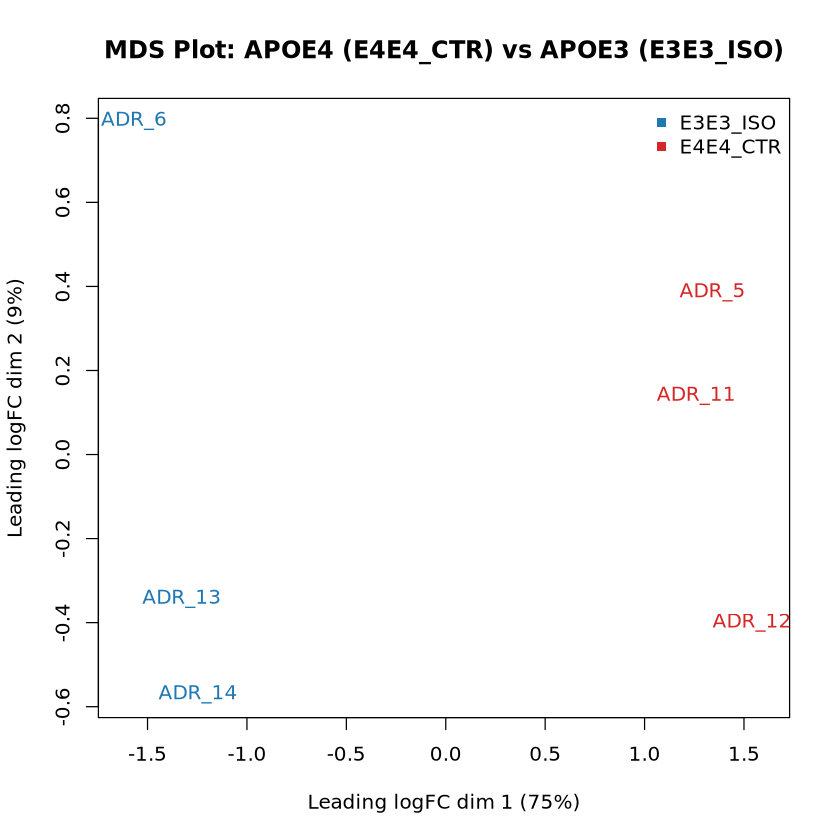

pdf 
  2

Significant in both:          5102 
Significant only in paper:    39 
Significant only in mine:     25 


,geneId,geneSymbol,logFC_mine,FDR_mine,FDR_author
,<chr>,<chr>,<dbl>,<dbl>,<dbl>
7976,ENSG00000151693,ASAP2,0.3926029,0.05004955,0.04481857
4597,ENSG00000122642,FKBP9,-0.3834922,0.05033481,0.04583940
13335,ENSG00000197728,RPS26,-0.3911221,0.05027994,0.04604726
7812,ENSG00000149600,COMMD7,-0.4117779,0.05150740,0.04624903
2776,ENSG00000105640,RPL18A,-0.3888776,0.05027994,0.04654553
5487,ENSG00000131378,RFTN1,-0.4193333,0.05043252,0.04654553
14685,ENSG00000230461,PROX1-AS1,0.9676131,0.05026608,0.04686443
9474,ENSG00000164366,CCDC127,0.4121892,0.05161383,0.04695283
9387,ENSG00000164080,RAD54L2,0.3983922,0.05086027,0.04712448


[1] 0.04482370 0.05648735

[1] 0.04481857 0.05560122

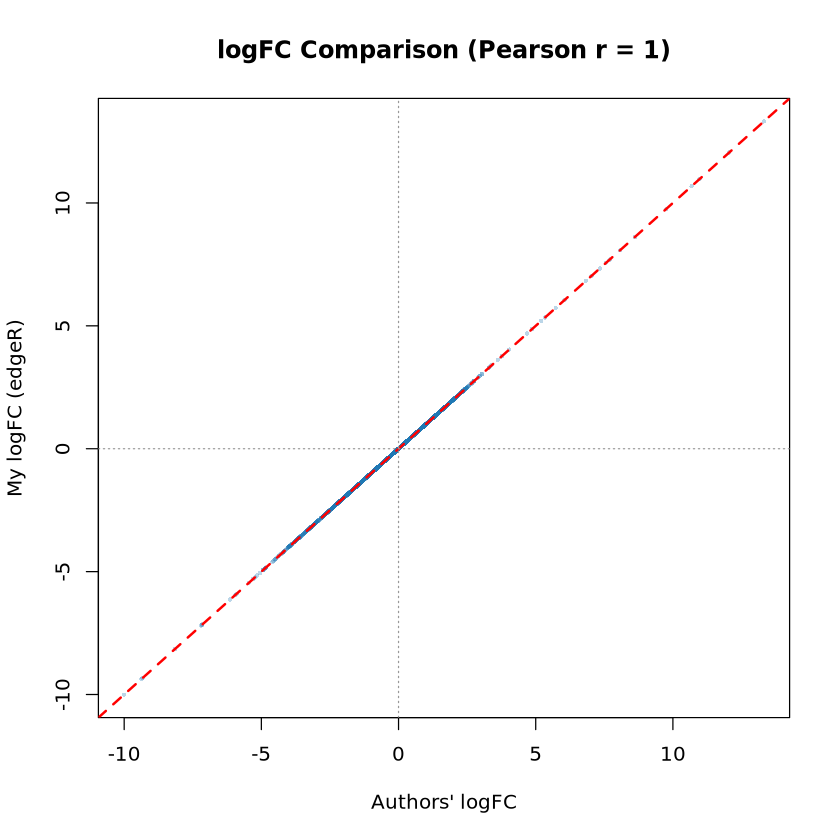

In [3]:
# 6. TMM normalisation and MDS plot
y <- normLibSizes(y, method = "TMM")
y$samples
y$samples$norm.factors

group_colors <- c("E3E3_ISO" = "#1f77b4", "E4E4_CTR" = "#d62728")
sample_colors <- group_colors[as.character(y$samples$group)]

out_dir <- "../images"
dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)

draw_mds <- function() {
  par(bg = "white")
  plotMDS(y, col = sample_colors, main = "MDS Plot: APOE4 (E4E4_CTR) vs APOE3 (E3E3_ISO)")
  legend("topright", legend = names(group_colors), col = group_colors, pch = 15, bty = "n")
}

draw_mds()                          # shows in the notebook
png(file.path(out_dir, "mds_plot.png"), width = 7, height = 7, units = "in", res = 300, bg = "white")
draw_mds()                          # saves to file
dev.off()

# 7. Design, dispersion and likelihood ratio test
design <- model.matrix(~ group, data = y$samples)
y <- estimateDisp(y, design)
fit <- glmFit(y, design)
lrt <- glmLRT(fit, coef = 2)
res <- topTags(lrt, n = Inf)$table


# 8. Count significant genes (paper: 5,141)
FDR_data <- subset(res, FDR < 0.05)
FDR_count <- nrow(FDR_data)
print(paste0("Total count for FDR less than 0.05: ", FDR_count))
logFC_count_1 <- sum(FDR_data$logFC > 0)
print(paste0("Total count for logFC greater than 0: ", logFC_count_1))
logFC_count_2 <- sum(FDR_data$logFC < 0)
print(paste0("Total count for logFC less than 0: ", logFC_count_2))
stopifnot(logFC_count_1 + logFC_count_2 == FDR_count)

# 9. Compare with Table S6: fold changes and overlap
results_table <- read_excel("../data/meyer2019_tableS6_organoid_DEGs.xlsx", sheet=1)
res$geneId <- rownames(res)
head(results_table)
merged_table <- merge(res, results_table, by="geneId", all.x = TRUE, suffixes = c("_mine", "_author"))
stopifnot(sum(is.na(merged_table$logFC_author)) == 0)
stopifnot(nrow(merged_table) == PAPER_FILTERED_GENES)
colnames(merged_table)

pearson_r <- cor(merged_table$logFC_mine, merged_table$logFC_author, method="pearson")
spearman_r <- cor(merged_table$logFC_mine, merged_table$logFC_author, method="spearman")

print(paste0("Pearson r:  ", round(pearson_r, 5)))
print(paste0("Spearman r: ", round(spearman_r, 5)))

draw_logfc_comparison <- function() {
  par(bg = "white")
  plot(merged_table$logFC_author, merged_table$logFC_mine,
       pch = 16, cex = 0.5,
       col = rgb(0.12, 0.47, 0.71, alpha = 0.3),
       xlab = "Authors' logFC",
       ylab = "My logFC (edgeR)",
       main = paste0("logFC Comparison (Pearson r = ", round(pearson_r, 4), ")"))
  abline(a = 0, b = 1, col = "red", lwd = 2, lty = 2)
  abline(h = 0, v = 0, col = "gray60", lty = 3)
}

draw_logfc_comparison()   # shows in the notebook

png(file.path(out_dir, "logfc_comparison.png"),
    width = 7, height = 7, units = "in", res = 300, bg = "white")
draw_logfc_comparison()   # saves to file
dev.off()

my_sig <- res$geneId[res$FDR < 0.05]
stopifnot(length(my_sig) == MY_SIG_GENES)
paper_sig <- results_table$geneId[results_table$FDR < 0.05]
stopifnot(length(paper_sig) == PAPER_SIG_GENES)
sig_both       <- intersect(my_sig, paper_sig)
sig_only_paper <- setdiff(paper_sig, my_sig)
sig_only_mine  <- setdiff(my_sig, paper_sig)

cat("Significant in both:         ", length(sig_both), "\n")
cat("Significant only in paper:   ", length(sig_only_paper), "\n")
cat("Significant only in mine:    ", length(sig_only_mine), "\n")

disagree <- merged_table[merged_table$geneId %in% c(sig_only_paper, sig_only_mine),
                         c("geneId", "geneSymbol", "logFC_mine", "FDR_mine", "FDR_author")]
disagree[order(disagree$FDR_author), ]

range(disagree$FDR_mine)
range(disagree$FDR_author)

# Result of this reproduction (edgeR 4.10.7), used as a regression check


In [4]:
#Writing res file into a csv and saving in results folder
res_df <- as.data.frame(res)
res_df <- cbind(gene_id = rownames(res_df), res_df)
out_dir <- "../results"
dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)

write.csv(
  res_df,
  file = file.path(out_dir, "edger_results.csv"),
  row.names = FALSE
)

In [13]:
#Writing another table to do dispersion comparison

dispersion_edgeR_data <- data.frame()
dispersion_edgeR_data <- cbind(gene_id = rownames(y), dispersions = y$tagwise.dispersion)
dispersion_edgeR_data

write.csv(
  dispersion_edgeR_data,
  file = file.path(out_dir, "edgeR_dispersion_results.csv"),
  row.names = FALSE
)

gene_id,dispersions
ENSG00000000003,0.0281572044245463
ENSG00000000419,0.0247093770214173
ENSG00000000457,0.0177409271882767
ENSG00000000460,0.0249058615414359
ENSG00000000971,0.0324133585877236
ENSG00000001036,0.0211235446746763
ENSG00000001084,0.0267220553447887
ENSG00000001167,0.0185410173453303
ENSG00000001460,0.0202105967800352
ENSG00000001461,0.0181081654383606


In [10]:
rownames(y)

[1] "ENSG00000000003" "ENSG00000000419" "ENSG00000000457" "ENSG00000000460"
    [5] "ENSG00000000971" "ENSG00000001036" "ENSG00000001084" "ENSG00000001167"
    [9] "ENSG00000001460" "ENSG00000001461" "ENSG00000001497" "ENSG00000001561"
   [13] "ENSG00000001617" "ENSG00000001626" "ENSG00000001629" "ENSG00000001630"
   [17] "ENSG00000001631" "ENSG00000002016" "ENSG00000002330" "ENSG00000002549"
   [21] "ENSG00000002586" "ENSG00000002587" "ENSG00000002746" "ENSG00000002822"
   [25] "ENSG00000002834" "ENSG00000002919" "ENSG00000002933" "ENSG00000003056"
   [29] "ENSG00000003096" "ENSG00000003137" "ENSG00000003147" "ENSG00000003249"
   [33] "ENSG00000003393" "ENSG00000003400" "ENSG00000003402" "ENSG00000003436"
   [37] "ENSG00000003509" "ENSG00000003756" "ENSG00000003987" "ENSG00000003989"
   [41] "ENSG00000004059" "ENSG00000004139" "ENSG00000004142" "ENSG00000004399"
   [45] "ENSG00000004455" "ENSG00000004478" "ENSG00000004487" "ENSG00000004534"
   [49] "ENSG00000004660" "ENSG00000004700" "ENSG00000004766" "ENSG00000004776"
   [53] "ENSG00000004777" "ENSG00000004779" "ENSG00000004799" "ENSG00000004838"
   [57] "ENSG00000004848" "ENSG00000004864" "ENSG00000004866" "ENSG00000004897"
   [61] "ENSG00000004939" "ENSG00000004961" "ENSG00000004975" "ENSG00000005001"
   [65] "ENSG00000005007" "ENSG00000005020" "ENSG00000005022" "ENSG00000005059"
   [69] "ENSG00000005073" "ENSG00000005075" "ENSG00000005100" "ENSG00000005102"
   [73] "ENSG00000005108" "ENSG00000005156" "ENSG00000005175" "ENSG00000005187"
   [77] "ENSG00000005189" "ENSG00000005194" "ENSG00000005206" "ENSG00000005238"
   [81] "ENSG00000005243" "ENSG00000005249" "ENSG00000005302" "ENSG00000005339"
   [85] "ENSG00000005379" "ENSG00000005381" "ENSG00000005436" "ENSG00000005448"
   [89] "ENSG00000005469" "ENSG00000005483" "ENSG00000005486" "ENSG00000005513"
   [93] "ENSG00000005700" "ENSG00000005801" "ENSG00000005810" "ENSG00000005812"
   [97] "ENSG00000005844" "ENSG00000005882" "ENSG00000005884" "ENSG00000005889"
  [101] "ENSG00000005893" "ENSG00000005961" "ENSG00000006007" "ENSG00000006015"
  [105] "ENSG00000006016" "ENSG00000006025" "ENSG00000006042" "ENSG00000006047"
  [109] "ENSG00000006062" "ENSG00000006071" "ENSG00000006118" "ENSG00000006125"
  [113] "ENSG00000006128" "ENSG00000006194" "ENSG00000006210" "ENSG00000006282"
  [117] "ENSG00000006283" "ENSG00000006327" "ENSG00000006432" "ENSG00000006451"
  [121] "ENSG00000006453" "ENSG00000006459" "ENSG00000006468" "ENSG00000006530"
  [125] "ENSG00000006534" "ENSG00000006576" "ENSG00000006607" "ENSG00000006611"
  [129] "ENSG00000006625" "ENSG00000006634" "ENSG00000006638" "ENSG00000006652"
  [133] "ENSG00000006695" "ENSG00000006704" "ENSG00000006712" "ENSG00000006715"
  [137] "ENSG00000006740" "ENSG00000006744" "ENSG00000006747" "ENSG00000006756"
  [141] "ENSG00000006757" "ENSG00000006831" "ENSG00000007047" "ENSG00000007062"
  [145] "ENSG00000007080" "ENSG00000007168" "ENSG00000007171" "ENSG00000007174"
  [149] "ENSG00000007202" "ENSG00000007237" "ENSG00000007255" "ENSG00000007264"
  [153] "ENSG00000007314" "ENSG00000007341" "ENSG00000007350" "ENSG00000007372"
  [157] "ENSG00000007376" "ENSG00000007384" "ENSG00000007392" "ENSG00000007402"
  [161] "ENSG00000007516" "ENSG00000007520" "ENSG00000007541" "ENSG00000007545"
  [165] "ENSG00000007866" "ENSG00000007923" "ENSG00000007944" "ENSG00000007968"
  [169] "ENSG00000008018" "ENSG00000008056" "ENSG00000008083" "ENSG00000008086"
  [173] "ENSG00000008118" "ENSG00000008130" "ENSG00000008196" "ENSG00000008226"
  [177] "ENSG00000008256" "ENSG00000008277" "ENSG00000008282" "ENSG00000008283"
  [181] "ENSG00000008294" "ENSG00000008300" "ENSG00000008311" "ENSG00000008323"
  [185] "ENSG00000008324" "ENSG00000008382" "ENSG00000008394" "ENSG00000008405"
  [189] "ENSG00000008441" "ENSG00000008513" "ENSG00000008517" "ENSG00000008710"
  [193] "ENSG00000008735" "ENSG00000008838" "ENSG00000008853" "ENSG00000008869"
  [197] "ENSG00000008952" "ENSG00000008988" "ENSG00000009307" "ENSG00000009335"
  [2